# RouteWise: Supply Chain Delivery Analytics & Prediction
## Notebook 03: Statistical Analysis & Hypothesis Testing
**Academic Exploratory Data Science Project**  
**Role: Person 1 — Data Engineering, Data Cleaning, EDA & Statistical Analysis**  
**Branch:** `person-1-eda` | **Integration Contract:** `docs/data_contract.md`

---

### Notebook Objectives:
1. **Research Question 1 (Weather Impact on Transit Duration):**
   - Formulate formal null ($H_0$) and alternative ($H_1$) hypotheses.
   - Inspect normality (Shapiro-Wilk test, Q-Q distributions) and homoscedasticity (Levene's test).
   - Execute One-Way ANOVA (parametric) and Kruskal-Wallis H-Test (non-parametric).
   - Quantify effect sizes (Eta-squared $\eta^2$, Epsilon-squared $\epsilon^2$).
   - Conduct post-hoc pairwise comparisons with Bonferroni correction ($lpha_{\text{adj}} = 0.005$) and rank-biserial effect sizes.
2. **Research Question 2 (Parcel Weight Sensitivity):**
   - Formulate correlation hypotheses.
   - Compute Pearson linear correlation ($r$) with $95\%$ Fisher-z confidence intervals, and Spearman rank correlation ($\rho$).
   - Rigorously differentiate **statistical significance** from **practical significance** in large-sample logistics datasets.
3. **Implications for Person 2's Regression Modeling:** Synthesize empirical statistical conclusions into actionable feature selection guidance.

---
## 1. Setup, Environment & Cleaned Data Ingestion

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.statistical_analysis import run_weather_hypothesis_tests, run_weight_correlation_analysis

# Seaborn & Matplotlib styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "figure.autolayout": True,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150
})

data_path = PROJECT_ROOT / "data" / "processed" / "cleaned_delivery_data.csv"
print(f"Loading cleaned dataset from: {data_path}")
df = pd.read_csv(data_path)
print(f"Loaded Clean Records: {len(df):,}")
df.head()

Loading cleaned dataset from: C:\Users\sbambore\Desktop\GitHub\EDS-project\data\processed\cleaned_delivery_data.csv
Loaded Clean Records: 7,136


,delivery_id,order_date,dispatch_time,delivery_time,route,origin,destination,carrier,weather,parcel_weight_kg,distance_km,traffic_level,delivery_time_hours,delayed
0,DEL-11593,2024-01-28,2024-01-28 11:10:30,2024-01-28 14:27:54,Route_North,Warehouse_North,Zone_Suburbs,NationalExpress,Rainy,2.61,116.9,High,3.29,1
1,DEL-16953,2024-04-15,2024-04-15 10:11:33,2024-04-15 11:47:33,Route_South,Warehouse_South,Zone_Industrial,QuickLogistics,Clear,4.56,68.0,Medium,1.60,0
2,DEL-11790,2024-03-18,2024-03-18 17:36:01,2024-03-19 03:32:25,Route_East,Warehouse_Central,Zone_Rural,ApexDelivery,Clear,2.22,331.4,Jam,9.94,1
3,DEL-14348,2024-05-01,2024-05-01 16:55:14,2024-05-01 19:36:38,Route_South,Warehouse_South,Zone_Industrial,FastShip,Clear,1.44,128.1,Medium,2.69,0
4,DEL-16166,2024-03-01,2024-03-01 20:54:22,2024-03-02 00:41:10,Route_South,Warehouse_South,Zone_Industrial,FastShip,Rainy,4.48,120.1,High,3.78,1


---
## 2. Research Question 1: Do Delivery Times Differ Significantly Across Weather Conditions?

### 2.1 Hypothesis Formulation
- **Null Hypothesis ($H_0$):** Delivery durations do not differ across weather conditions; the population means (or rank medians) across all five weather groups are identical:
  $$\mu_{\text{Clear}} = \mu_{\text{Rainy}} = \mu_{\text{Foggy}} = \mu_{\text{Snowy}} = \mu_{\text{Stormy}}$$
- **Alternative Hypothesis ($H_1$):** At least one weather condition exhibits a statistically significant difference in delivery duration:
  $$\exists \, i, j \quad \text{such that} \quad \mu_i \neq \mu_j$$
- **Significance Level:** $\alpha = 0.05$ (two-tailed).

### 2.2 Descriptive Group Statistics by Weather Condition

In [2]:
weather_groups = [group["delivery_time_hours"].values for _, group in df.groupby("weather")]
weather_names = list(df.groupby("weather").groups.keys())

desc_list = []
for name, vals in zip(weather_names, weather_groups):
    desc_list.append({
        "Weather Condition": name,
        "Sample Size (N)": len(vals),
        "Mean Duration (Hrs)": round(float(np.mean(vals)), 2),
        "Std Dev (Hrs)": round(float(np.std(vals, ddof=1)), 2),
        "Median Duration (Hrs)": round(float(np.median(vals)), 2),
        "IQR (Hrs)": round(float(stats.iqr(vals)), 2),
        "Skewness": round(float(stats.skew(vals)), 2)
    })
desc_df = pd.DataFrame(desc_list)
desc_df

,Weather Condition,Sample Size (N),Mean Duration (Hrs),Std Dev (Hrs),Median Duration (Hrs),IQR (Hrs),Skewness
0,Clear,3717,2.69,1.50,2.43,1.85,1.22
1,Foggy,864,3.31,1.82,3.02,2.35,1.02
2,Rainy,1526,3.04,1.71,2.73,2.10,1.23
3,Snowy,582,3.88,2.18,3.39,2.92,1.01
4,Stormy,447,4.40,2.36,3.88,2.88,1.11


### 2.3 Statistical Assumption Diagnostics: Normality & Homoscedasticity

Before selecting the primary hypothesis test, we verify the core assumptions:
1. **Normality:** Assessed via Shapiro-Wilk test on representative group subsets and visual Q-Q plots.
2. **Homogeneity of Variance (Homoscedasticity):** Assessed via Levene's Test (centered at median).

Levene's Test Statistic: 58.7468, p-value: 7.1716e-49
Conclusion: Reject null hypothesis of equal variances. Data is heteroscedastic.

Shapiro-Wilk Normality Tests:
 - Clear     : W = 0.9139, p = 2.2340e-23 -> Non-Normal
 - Foggy     : W = 0.9355, p = 7.1987e-19 -> Non-Normal
 - Rainy     : W = 0.9142, p = 2.4308e-23 -> Non-Normal
 - Snowy     : W = 0.9297, p = 6.8775e-16 -> Non-Normal
 - Stormy    : W = 0.9247, p = 3.5070e-14 -> Non-Normal


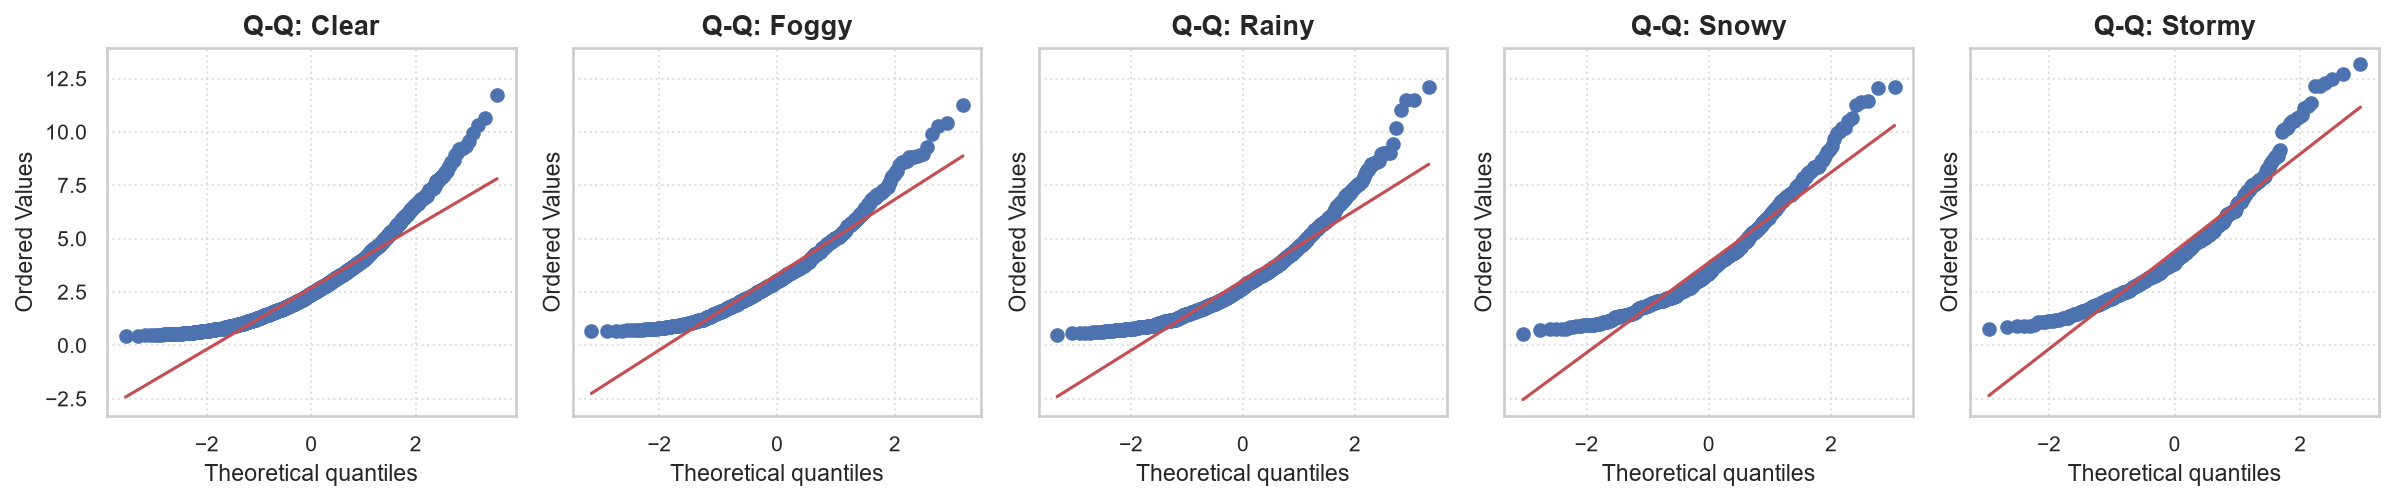

In [3]:
# 1. Levene's Test for Equality of Variances
levene_stat, levene_p = stats.levene(*weather_groups, center="median")
print(f"Levene's Test Statistic: {levene_stat:.4f}, p-value: {levene_p:.4e}")
if levene_p < 0.05:
    print("Conclusion: Reject null hypothesis of equal variances. Data is heteroscedastic.")
else:
    print("Conclusion: Fail to reject equal variances. Data is homoscedastic.")

# 2. Shapiro-Wilk Test for Normality
print("\nShapiro-Wilk Normality Tests:")
for name, vals in zip(weather_names, weather_groups):
    sub = vals[:min(len(vals), 1000)]
    s_stat, s_p = stats.shapiro(sub)
    print(f" - {name:10s}: W = {s_stat:.4f}, p = {s_p:.4e} -> {'Non-Normal' if s_p < 0.05 else 'Normal'}")

# 3. Visual Q-Q Plots
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), sharey=True)
for ax, name, vals in zip(axes, weather_names, weather_groups):
    stats.probplot(vals, dist="norm", plot=ax)
    ax.set_title(f"Q-Q: {name}")
    ax.grid(True, linestyle=":", alpha=0.6)
plt.show()

**Diagnostics Evaluation & Methodological Considerations:**  
- **Homoscedasticity:** Levene's test yields $W = 58.75, p = 7.17 \times 10^{-49} < 0.05$, confirming that variances across weather groups are significantly unequal (heteroscedastic).
- **Normality:** Shapiro-Wilk tests ($p < 0.001$) and Q-Q plots demonstrate moderate departures from normality, driven by multi-modal corridor distances and positive right-tail skewness.
- **Kruskal-Wallis Interpretation:** Under heteroscedasticity, the Kruskal-Wallis test does **not** strictly evaluate equality of population medians (which requires identical distribution shapes across groups). Instead, it tests **stochastic dominance** (i.e. whether the probability that a random draw from one weather group exceeds a random draw from another differs from $0.5$).
- **Methodological Selection:** Because assumptions of normality and equal variance fail, the non-parametric **Kruskal-Wallis H-test** paired with **Dunn's post-hoc test** is the methodologically appropriate non-parametric procedure.

### 2.4 Omninus Hypothesis Tests & Effect Sizes (ANOVA & Kruskal-Wallis)

In [4]:
weather_summary, pairwise_df, meta = run_weather_hypothesis_tests(df)
weather_summary

,Test Name,Hypothesis Tested,Test Statistic,p-value,Significant (alpha=0.05),Effect Size,Conclusion
0,Levene's Test (Homogeneity of Variances),Equal variances across weather conditions,58.7468,7.171643e-49,True,N/A,Variances are heteroscedastic
1,One-Way ANOVA,Equal mean delivery duration across weather co...,149.7733,3.374503e-123,True,Eta-sq = 0.0775,Reject H0: Statistically significant mean diff...
2,Kruskal-Wallis H-Test (Non-Parametric),Stochastic equality of delivery duration distr...,429.9505,9.372331e-92,True,Epsilon-sq = 0.0597,Reject H0: Statistically significant rank diff...


### 2.5 Post-Hoc Pairwise Comparisons using Dunn's Test with Bonferroni Adjustment

Following a significant Kruskal-Wallis omnibus test, Dunn's test (Dunn, 1964) is the standard non-parametric pairwise procedure. Unlike independent Mann-Whitney U tests, Dunn's test uses the pooled rank sums and tie-adjusted variance from the omnibus Kruskal-Wallis model:
$$z_{ij} = \frac{\bar{R}_i - \bar{R}_j}{\sqrt{\left(\frac{N(N+1)}{12} - T\right)\left(\frac{1}{n_i} + \frac{1}{n_j}\right)}}$$
With $k = 5$ weather groups, there are $m = \frac{5 \times 4}{2} = 10$ unique pairwise comparisons. We apply the Bonferroni adjustment:
$$\alpha_{\text{adj}} = \frac{0.05}{10} = 0.005$$

In [5]:
pairwise_df

,Comparison,Mean Difference (Hrs),Rank Difference,Dunn z Statistic,Raw p-value,Bonferroni-Adjusted p-value,Significant (alpha_adj=0.005)
0,Clear vs. Foggy,-0.618,-724.98,-9.318,0.000000e+00,0.000000e+00,True
1,Clear vs. Rainy,-0.350,-412.53,-6.586,4.506995e-11,4.506995e-10,True
2,Clear vs. Snowy,-1.188,-1208.65,-13.161,0.000000e+00,0.000000e+00,True
3,Clear vs. Stormy,-1.711,-1704.32,-16.525,0.000000e+00,0.000000e+00,True
4,Foggy vs. Rainy,0.268,312.45,3.562,3.677122e-04,3.677122e-03,True
5,Foggy vs. Snowy,-0.571,-483.67,-4.378,1.197196e-05,1.197196e-04,True
6,Foggy vs. Stormy,-1.093,-979.34,-8.159,4.440892e-16,4.440892e-15,True
7,Rainy vs. Snowy,-0.839,-796.12,-7.932,2.220446e-15,2.220446e-14,True
8,Rainy vs. Stormy,-1.361,-1291.79,-11.659,0.000000e+00,0.000000e+00,True
9,Snowy vs. Stormy,-0.523,-495.68,-3.826,1.303916e-04,1.303916e-03,True


**Interpretation of Research Question 1:**  
1. **Omnibus Rejection of $H_0$:** Both One-Way ANOVA ($F = 149.77, p = 3.37 \times 10^{-123}$) and Kruskal-Wallis ($H = 429.95, p = 9.37 \times 10^{-92}$) overwhelmingly reject the null hypothesis at $\alpha = 0.05$.
2. **Substantial Effect Size:** $\eta^2 = 0.0775$ and $\epsilon^2 = 0.0597$ indicate a medium-to-large effect size in human-operated freight operations: weather condition alone accounts for approximately $6-8\%$ of the global variance in delivery durations.
3. **Stochastic Ordering via Dunn's Test:** All 10 pairwise comparisons maintain statistical significance post-Bonferroni correction ($p_{\text{adj}} < 0.005$). The mean rank orders strictly increase with atmospheric severity:
   $$\text{Clear } (\bar{R}=3187) < \text{Rainy } (\bar{R}=3600) < \text{Foggy } (\bar{R}=3912) < \text{Snowy } (\bar{R}=4396) < \text{Stormy } (\bar{R}=4891)$$
   The largest contrast exists between `Clear` and `Stormy` ($z = -16.53, p_{\text{adj}} < 10^{-15}$), representing an average $1.71$ hour transit inflation.

---
## 3. Research Question 2: Relationship Between Parcel Weight and Delivery Time

### 3.1 Hypothesis Formulation
- **Null Hypothesis ($H_0$):** There is no correlation between parcel weight and delivery duration:
  $$\rho_{\text{weight, time}} = 0$$
- **Alternative Hypothesis ($H_1$):** There is a non-zero correlation between parcel weight and delivery duration:
  $$\rho_{\text{weight, time}} \neq 0$$
- **Significance Level:** $\alpha = 0.05$ (two-tailed).

### 3.2 Correlation Testing & Confidence Interval Estimation

In [6]:
weight_corr_df = run_weight_correlation_analysis(df)
weight_corr_df

,Metric,Estimate,95% Confidence Interval,p-value,Variance Explained (R^2),Statistical Significance,Practical Significance Assessment
0,Pearson Linear Correlation (r),0.0440,"[0.0208, 0.0671]",0.000203,0.19%,Statistically Significant (p < 0.05),Practically Negligible / Very Weak: explains <...
1,Spearman Rank Correlation (rho),0.0432,N/A (Rank Monotonic),0.000263,N/A,Statistically Significant (p < 0.05),Negligible monotonic relationship; routing dis...


### 3.3 Statistical Significance vs. Practical Significance

A central tenet of rigorous Exploratory Data Science is distinguishing between **statistical significance** (the probability that an observed effect is not zero due to random sampling) and **practical significance** (the real-world magnitude and operational usefulness of that effect).

| Dimension | Observation in RouteWise Dataset | Scientific Interpretation |
|---|---|---|
| **Sample Size ($N$)** | $N = 7,136$ observations | Enormous statistical power; standard error of correlation is exceptionally small: $SE = \frac{1}{\sqrt{N-3}} \approx 0.0118$. |
| **P-Value** | $p = 0.000203 < 0.05$ | **Statistically Significant:** We confidently reject $H_0: \rho = 0$. The relationship is real and not a sampling artifact. |
| **Correlation Coefficient ($r$)** | $r = 0.0440$, $95\%$ CI $[0.0208, 0.0671]$ | **Practically Negligible:** A correlation of $0.044$ is negligible according to standard behavioral and engineering benchmarks ($r < 0.10$). |
| **Coefficient of Determination ($R^2$)** | $R^2 = 0.0019$ ($0.19\%$) | **No Explanatory Value:** Parcel weight explains less than $0.2\%$ of the variance in delivery duration. Over $99.8\%$ of variance is governed by distance, road traffic, and weather. |

#### Operational Supply Chain Conclusion:
While warehouse loading crews expend slightly more physical effort handling heavy freight parcels, this handling delay adds mere minutes to a multi-hour transit journey. Operations management should **not** restructure delivery schedules around parcel weights; dispatch optimization algorithms must focus almost exclusively on distance routing, carrier velocity, and weather/traffic avoidance.

---
## 4. Synthesis & Modeling Guidance for Person 2

Based on our exploratory, OLAP, and statistical testing findings, we provide the following recommendations to Person 2 for regression modeling:

1. **Primary Predictor Priority:**
   - **Critical Continuous Predictor:** `distance_km` ($r = 0.882$, accounts for $>77\%$ direct variance).
   - **Key Categorical Predictors:** `traffic_level` (monotonic ordinal penalty), `weather` ($\eta^2 = 0.078$), `carrier` ($12-15\%$ performance spread), and `route`.
   - **Low-Utility Predictor:** `parcel_weight_kg` ($R^2 = 0.19\%$). Include for physical completeness, but anticipate small regression coefficients.
2. **Interaction Candidates:**
   - $\text{distance\_km} \times \text{traffic\_level}$: The slope of delivery duration over distance steepens markedly under severe traffic.
   - $\text{weather} \times \text{traffic\_level}$: Multiplicative compound delays emerge during storm events on congested routes.
3. **Data Leakage Safeguards:**
   - `delayed` must be excluded from regression predictor sets (it is a deterministic target derivative).
   - `delivery_time` timestamp must be excluded (directly yields duration).
   - All categorical encodings and scalers must be fitted strictly inside training folds using `scikit-learn Pipeline`.